In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import functools as ft
import statistics
import scipy as sc
import pingouin as ping
import hyppo as hyp

In [4]:
def get_pvalue_info_H1 (pvalue_generator, clr = "#00008B", label = "", level_array = [0.05, 0.01], mode_output = 0):
    table = [0]*len(level_array) # на i-ом месте стоит частота отвержения гипотезы на уровне alpha_i
    pvalue = pvalue_generator()
    N = len(pvalue)
    alpha = level_array

    if(N < 5):
        print("how am i supposed to test your criterion based on < 5 p-value values?", end = "\n")
        print("как я должен тестить ваш критерий, основываясь на < 5 значениях p-value?", end = "\n")
        print("anyway: ", end = "\n")

    for j in range ( len(alpha) ):
        freq = 0
        for p in pvalue:
            if p<alpha[j]:
                freq+=1/N
        table[j] = freq
        # заполнили табличку

    if(mode_output == 0): #на экран ничего, только возвращаем табличку
        return(table)

    if(mode_output == 1): # на экран только график ЭФР пи-вэлью
        l = np.linspace(0,1,100) # пока по умолчанию точность 1/100
        plt.legend()
        plt.title("график ЭФР пи-вэлью при вашей H1")
        plt.plot(l, sc.stats.ecdf(pvalue).cdf.evaluate(l), color = clr, label = label)
        plt.plot(l,l, color =  "#013220")
      
        return(table)

    if(mode_output == 2): #на экран только табличку
        for j in range ( len(level_array) ):
            print("частота отклонений H0 на уровне значимости ", alpha[j], ": ", table[j], end='\n')
        return(table)

    if(mode_output == 3): #на экран табличку и график ЭФР пи-вэлью
        l = np.linspace(0,1,100) # пока по умолчанию точность 1/100
        plt.title("график ЭФР пи-вэлью при вашей H1")
        plt.plot(l, sc.stats.ecdf(pvalue).cdf.evaluate(l), color = "#00008B")
        plt.plot(l,l, color = "#013220")
        plt.show()

        for j in range ( len(level_array) ):
             print("частота отклонений H0 на уровне значимости ", alpha[j], ": ", table[j], end='\n')
        return(table)

In [ ]:
1. Найти коэффициенты корреляции баллов ЕГЭ и частные коэффициенты корреляции и сделать выводы
о структуре их зависимости.

In [42]:
df = data=pd.read_csv("Dataset-18-Prak.csv", sep = ",", encoding="cp1251")
cols = df.columns
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        print("признаки:", i+1, j+1)
        print(ping.partial_corr(data = df, x = cols[i], y = cols[j]).r)
    print("\n")
    
for k in range(len(cols)):
    for i in range(len(cols)):
        for j in range(i+1, len(cols)):
            if i!=k and j!=k:
                print("признаки без:",k+1,": ", i+1, j+1)
                print(ping.partial_corr(data = df, covar = cols[k], x = cols[i], y = cols[j]).r)
        print("\n")

признаки: 1 2
pearson    0.51166
Name: r, dtype: float64
признаки: 1 3
pearson    0.432463
Name: r, dtype: float64
признаки: 1 4
pearson    0.123863
Name: r, dtype: float64


признаки: 2 3
pearson    0.436564
Name: r, dtype: float64
признаки: 2 4
pearson    0.218213
Name: r, dtype: float64


признаки: 3 4
pearson    0.254438
Name: r, dtype: float64






признаки без: 1 :  2 3
pearson    0.277743
Name: r, dtype: float64
признаки без: 1 :  2 4
pearson    0.19087
Name: r, dtype: float64


признаки без: 1 :  3 4
pearson    0.225276
Name: r, dtype: float64




признаки без: 2 :  1 3
pearson    0.270561
Name: r, dtype: float64
признаки без: 2 :  1 4
pearson    0.009765
Name: r, dtype: float64




признаки без: 2 :  3 4
pearson    0.17963
Name: r, dtype: float64




признаки без: 3 :  1 2
pearson    0.39805
Name: r, dtype: float64
признаки без: 3 :  1 4
pearson    0.015521
Name: r, dtype: float64


признаки без: 3 :  2 4
pearson    0.127329
Name: r, dtype: float64






признаки без: 4 :  1 

In [ ]:
2. Для распределений, изображенных на рисунке 1 (сгенерируйте выборки самостоятельно, размер вы-
борок 50 или 100), сравните критерии Секея-Риццо, Кендалла и хи-квадрат. Для распределения хи-
квадрат ячейки предлагается выбирать, деля данные по каждой из строк на равные фрагменты. Учтите,

что общее число ячеек должно быть много меньше, чем √

n, где n – число наблюдений!

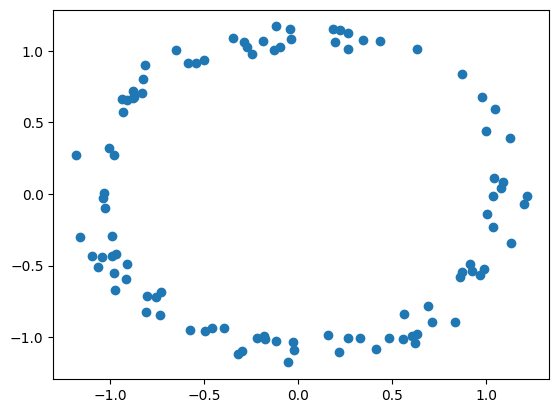

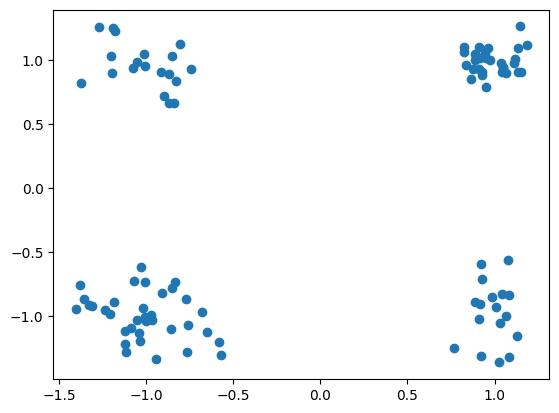

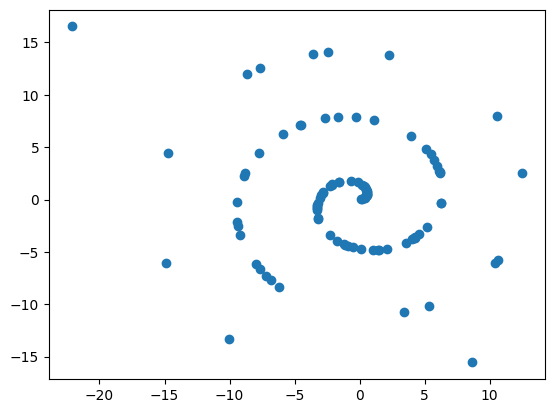

C:\Users\MI\AppData\Local\Temp\ipykernel_15256\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


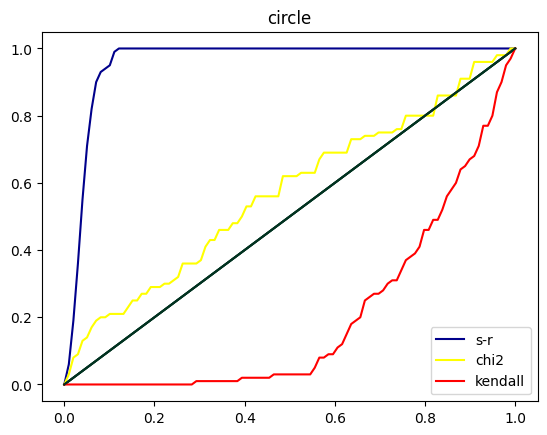

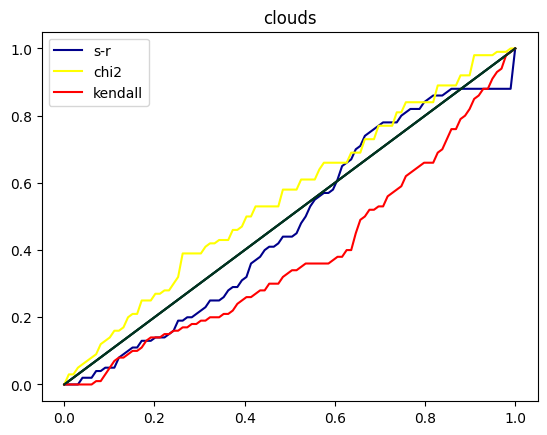

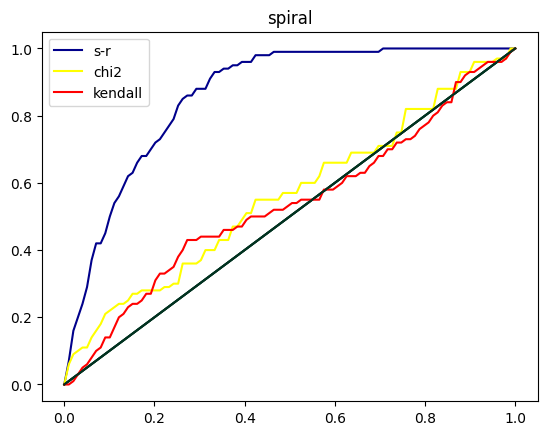

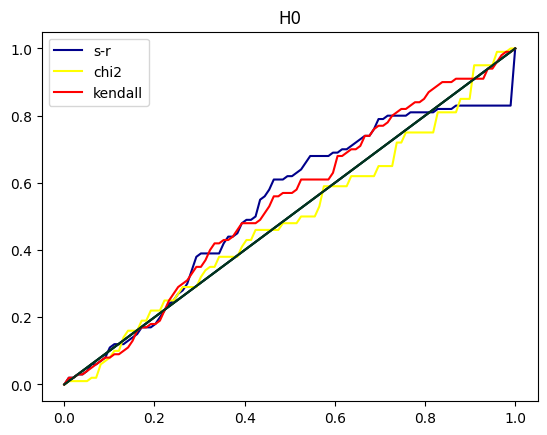

In [7]:
def a(x):
    return x
    
def chi2_pval(x, y):
    combined = np.concatenate([x, y])
    n = len(combined)
    k = max(3, int(round(n ** (1/5))))         
    bins = np.percentile(combined, np.linspace(0, 100, k+1))

    x_cat = np.digitize(x, bins[:-1]) - 1
    y_cat = np.digitize(y, bins[:-1]) - 1
    nx = np.bincount(x_cat, minlength=len(bins)-1)
    ny = np.bincount(y_cat, minlength=len(bins)-1)
    return sc.stats.chi2_contingency([nx, ny]).pvalue

    
def gen_circle(n):
    phi = np.random.uniform(0, 2*np.pi, size = n)
    r2 = np.random.uniform(1, 3/2, size = n)
    x = np.array([np.sqrt(r2[i])*np.cos(phi[i]) for i in range(n)] )
    y = np.array([np.sqrt(r2[i])*np.sin(phi[i]) for i in range(n)] )
    return x, y

def gen_clouds(n):
    x = [0]*n
    y = [0]*n
    for k in range(n):
        if np.random.binomial(1, 1/2) == 0:
            x[k] = np.random.normal(-1, 1/5)
            if np.random.binomial(1, 1/2) == 0:
                y[k] = np.random.normal(-1, 1/5)
            else:
                 y[k] = np.random.normal(1, 1/5)
        else:
            x[k] = np.random.normal(1, 1/10)
            if np.random.binomial(1, 1/2) == 0:
                y[k] = np.random.normal(-1, 1/5)
            else:
                 y[k] = np.random.normal(1, 1/10)
    return np.array(x), np.array(y)

def gen_spiral(n):
    phi = np.abs( np.random.normal(0,8, size = n) )
    r = phi
    x = [r[i] * np.cos( phi[i] ) for i in range(n)]
    y = [r[i] * np.sin( phi[i] ) for i in range(n)]
    return np.array(x), np.array(y)


def main_fun(pval_sr, pval_ken, pval_chi2, get_pvalue_info_H1, a):
    b = ft.partial(a, pval_sr)    
    get_pvalue_info_H1 (b, clr = "#00008B", label = "s-r", level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a, pval_chi2)    
    get_pvalue_info_H1 (b, clr = "yellow", label = "chi2", level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a, pval_ken)    
    get_pvalue_info_H1 (b, clr = "red", label = "kendall", level_array = [0.05, 0.01], mode_output = 1)
    
def pval(n, N, gen, chi2_pval):
    pval_sr = [0]*N 
    pval_ken = [0]*N
    pval_chi2 = [0]*N
    for k in range(N):
        x, y = gen(n)
        pval_sr[k] = hyp.independence.Dcorr().test(x,y)[1]
        pval_ken[k] = sc.stats.kendalltau(x, y).pvalue
        pval_chi2[k] = chi2_pval(x,y)
    return pval_sr, pval_ken, pval_chi2

n = 100
N = 100    
pval_sr = [0]*N 
pval_ken = [0]*N
pval_chi2 = [0]*N



x, y = gen_circle(n)
plt.scatter(x, y)
plt.show()

x, y = gen_clouds(n)
plt.scatter(x, y)
plt.show()

x, y = gen_spiral(n)
plt.scatter(x, y)
plt.show()



pval_sr, pval_ken, pval_chi2 = pval(n, N, gen_circle, chi2_pval)
main_fun(pval_sr, pval_ken, pval_chi2, get_pvalue_info_H1, a)
plt.legend()
plt.title("circle")
plt.show()

pval_sr, pval_ken, pval_chi2 = pval(n, N, gen_clouds, chi2_pval)
main_fun(pval_sr, pval_ken, pval_chi2, get_pvalue_info_H1, a)
plt.legend()
plt.title("clouds")
plt.show()

pval_sr, pval_ken, pval_chi2 = pval(n, N, gen_spiral, chi2_pval)
main_fun(pval_sr, pval_ken, pval_chi2, get_pvalue_info_H1, a)
plt.legend()
plt.title("spiral")
plt.show()

def r_gen(n):
    return (np.random.uniform(0,1, size = n), np.random.uniform(0,1, size = n))

pval_sr, pval_ken, pval_chi2 = pval(n, N, r_gen, chi2_pval)
main_fun(pval_sr, pval_ken, pval_chi2, get_pvalue_info_H1, a)
plt.legend()
plt.title("H0")
plt.show()

C:\Users\MI\AppData\Local\Temp\ipykernel_12440\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


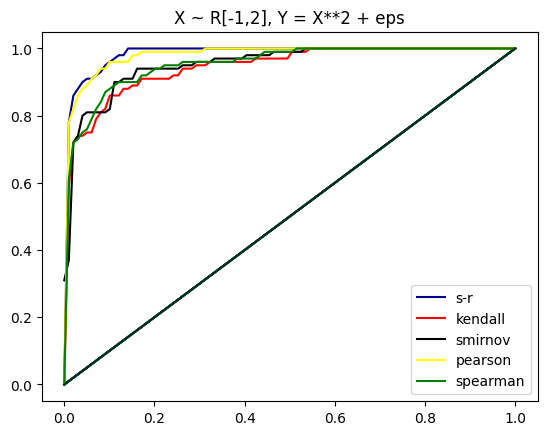

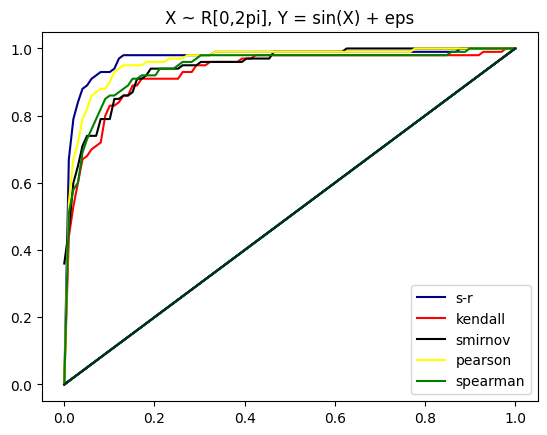

In [21]:
def a(x):
    return x

def gen1(n):
    x = np.random.uniform(-1,2, size=n)
    eps = np.random.normal(0, np.sqrt(1/2), size=n)
    y = x**2 + eps
    return x, y

def gen2(n):
    x = np.random.uniform(0,2*np.pi, size=n)
    eps = np.random.normal(0, np.sqrt(1/2), size=n)
    y = np.sin(x) + eps
    return x, y

def main_fun(pval_smir, pval_pears, pval_ken, pval_spear, pval_sr, get_pvalue_info_H1, a):
    b = ft.partial(a, pval_sr)    
    get_pvalue_info_H1 (b, clr = "#00008B", label = "s-r", level_array = [0.05, 0.01], mode_output = 1)

    b = ft.partial(a, pval_ken)    
    get_pvalue_info_H1 (b, clr = "red", label = "kendall", level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a, pval_smir)    
    get_pvalue_info_H1 (b, clr = "black", label = "smirnov", level_array = [0.05, 0.01], mode_output = 1)

    b = ft.partial(a, pval_pears)    
    get_pvalue_info_H1 (b, clr = "yellow", label = "pearson", level_array = [0.05, 0.01], mode_output = 1)

    b = ft.partial(a, pval_spear)    
    get_pvalue_info_H1 (b, clr = "green", label = "spearman", level_array = [0.05, 0.01], mode_output = 1)
    
def pval(n, N, gen):
    pval_smir = [0]*N 
    pval_pears = [0]*N
    pval_ken = [0]*N
    pval_spear = [0]*N
    pval_sr = [0]*N
    for k in range(N):
        x, y = gen(n)
        pval_sr[k] = hyp.independence.Dcorr().test(x,y)[1]
        pval_ken[k] = sc.stats.kendalltau(x, y).pvalue
        pval_pears[k] = sc.stats.pearsonr(x, y).pvalue
        pval_spear[k] = sc.stats.spearmanr(x, y).pvalue
        pval_smir[k] = 1 - sc.stats.ecdf(smirnov_loaded).cdf.evaluate(smirnov_stat(x, y))
    return pval_smir, pval_pears, pval_ken, pval_spear, pval_sr

def smirnov_stat(x, y):
    n = len(x)
    ecdf_x = sc.stats.ecdf(x).cdf
    ecdf_y = sc.stats.ecdf(y).cdf

    x_vals = np.unique(x)
    y_vals = np.unique(y)

    max_diff = 0.0

    for xi in x_vals:
        for yj in y_vals:
            Hn = np.mean((x <= xi) & (y <= yj))
            Fn = ecdf_x.evaluate(xi)
            Gn = ecdf_y.evaluate(yj)
            diff = abs(Hn - Fn * Gn)
            if diff > max_diff:
                max_diff = diff
    return np.sqrt(n) * max_diff

n = 20
N = 100
smirnov_loaded = np.loadtxt('smirnov test independence(10 obs).txt')

pval_smir, pval_pears, pval_ken, pval_spear, pval_sr = pval(n, N, gen1)
main_fun(pval_smir, pval_pears, pval_ken, pval_spear, pval_sr , get_pvalue_info_H1, a)
plt.legend()
plt.title("X ~ R[-1,2], Y = X**2 + eps")
plt.show()

pval_smir, pval_pears, pval_ken, pval_spear, pval_sr = pval(n, N, gen2)
main_fun(pval_smir, pval_pears, pval_ken, pval_spear, pval_sr , get_pvalue_info_H1, a)
plt.legend()
plt.title("X ~ R[0,2pi], Y = sin(X) + eps")
plt.show()